1.Loading the Taxis dataset

In [ ]:
import seaborn as sns

In [ ]:
df=sns.load_dataset('taxis')
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


2.Handling missing values

check for missing values in the dataset and identify columns with missing data

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


Impute missing  values using appropriate stratergies based on the column data type(use mean median or mode for numerical column and mode for categorical column)

there are missing values in 5 columns payment, pickup_zone, dropoff_zone,pickup_borough,dropoff_borough. we impute the missing values using mode


In [ ]:
df["pickup_zone"]=df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"]=df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"]=df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"]=df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

In [ ]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])

In [ ]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


mode() find the most frequent value.

[0] selects the first mode if multiple mode exists.

fillna() replace missing value with that value

3.Visualization using Matplotlib/pandas plot

LINE CHART

Plot a line chart to visualize the fare over time using the pickup timestamp as the x axis and fare as the y axis ensure the pickup column is converted to a datetime format before plotting

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

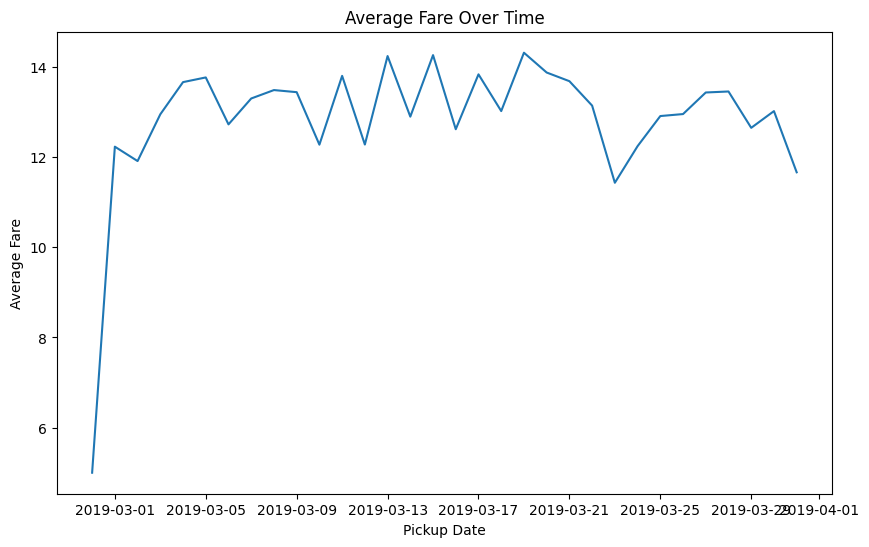

In [ ]:
plt.figure(figsize=(10,6))
df['pickup']=pd.to_datetime(df['pickup'])
daily_fare=df.groupby(df['pickup'].dt.date)['fare'].mean()
plt.plot(daily_fare.index,daily_fare.values)
plt.xlabel('Pickup Date')
plt.ylabel('Average Fare')
plt.title('Average Fare Over Time')
plt.show()


.dt.date extracts the date

groupby() groups trips by date

.mean() calculates the average fare for each date

plt.plot() creates the line chart

BAR CHART

Create a barchart to show the total fare for each pickup borough group the data by pickup borough and sum the fare for each group

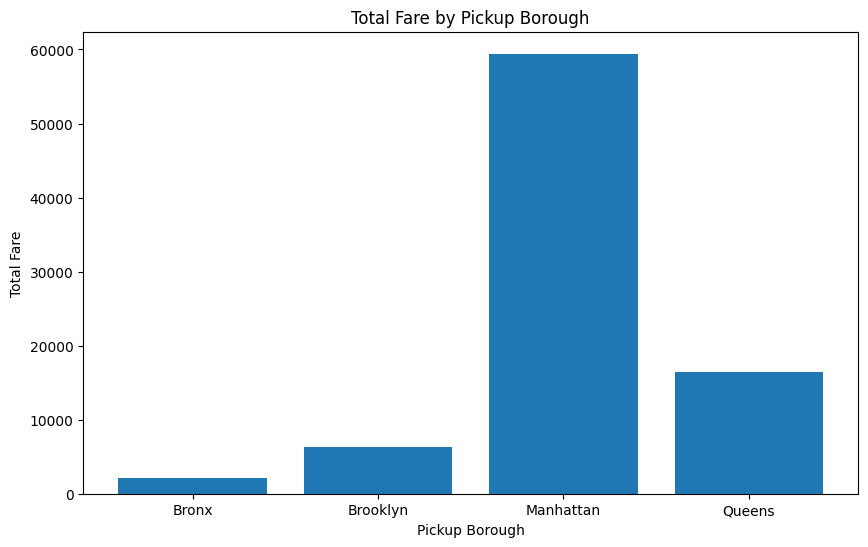

In [ ]:
borough_fare=df.groupby('pickup_borough')['fare'].sum()
plt.figure(figsize=(10,6))
plt.bar(borough_fare.index,borough_fare.values)
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.title('Total Fare by Pickup Borough')
plt.show()

groupby('pickup_borough') groups trips by pickup borough

['fare'].sum() calculates the total fare for each borough

plt.bar creates the bar chart

PIE CHART

Plot a pie chart showing the distribution of trips based on the payment method each slice should represent the count of trips for a specific payment method

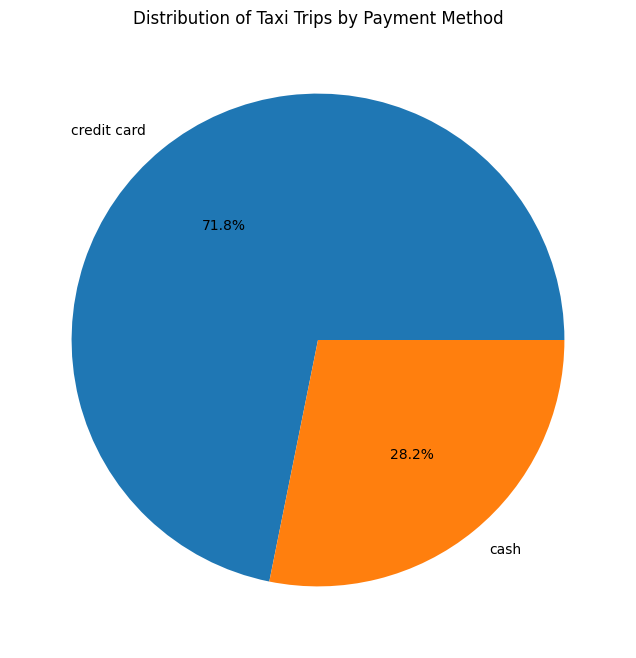

In [ ]:
payment_counts=df['payment'].value_counts()
plt.figure(figsize=(8,8))
plt.pie(payment_counts,labels=payment_counts.index,autopct='%1.1f%%')
plt.title('Distribution of Taxi Trips by Payment Method')
plt.show()

value_counts() counts trips for each payment mode

labels display the payment method name

autopct displays the percentage on the pie slice

plt.pie creates the pie chart

HISTOGRAM

Create a histogram to visualize the distribution of distance customize the number of bins for better granularity and ensure the plot is east to interpret


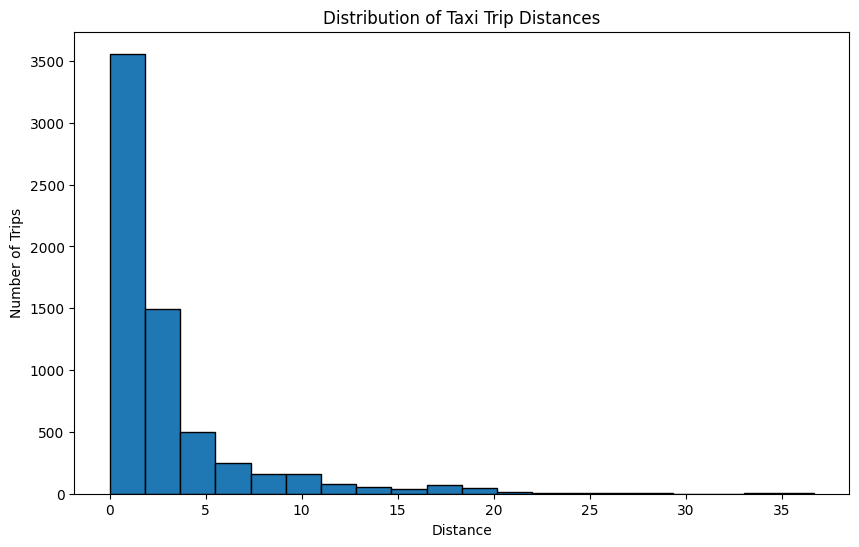

In [21]:
plt.figure(figsize=(10,6))
plt.hist(df['distance'],bins=20,edgecolor='black')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')
plt.title('Distribution of Taxi Trip Distances')
plt.show()


distance is the numerical value

bins=20 divides the distance into 20 intervals

edgecolor='black' makes the bin boundaries visible

plt.hist() creates a histogram

BOX PLOT

Plot a box plot to visualize the distribution of tip amount for each pickup borough use pickup borough as categorical axis and tip as the numeric axis

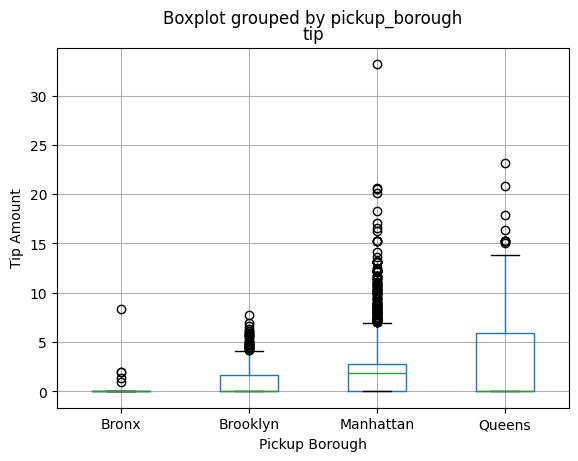

In [23]:
df.boxplot(column='tip',by='pickup_borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.show()


column='tip' specifies the numerical variable

by='pickup_borough' creates a seperate box for each borough

VISUALIZATION USING SEABORN

COUNT PLOT

Create a count plot to visualize the number of trips in each pickup borough the x axis should represent the boroughs and y axis should show the count of trips

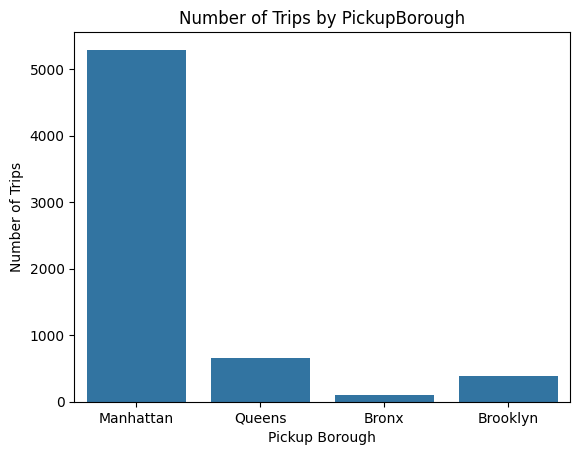

In [29]:
sns.countplot(x='pickup_borough',data=df)
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.title('Number of Trips by PickupBorough')
plt.show()

sns.countplot() counts how many rows belong to each category

SCATTER PLOT

Plot a scatter plot to show the relationship between distance andfare.use distance on x axis and fare on y axis tt visualize the correlation.color the points based on pickup borough to differentiate the trips by their corressponding boroughs

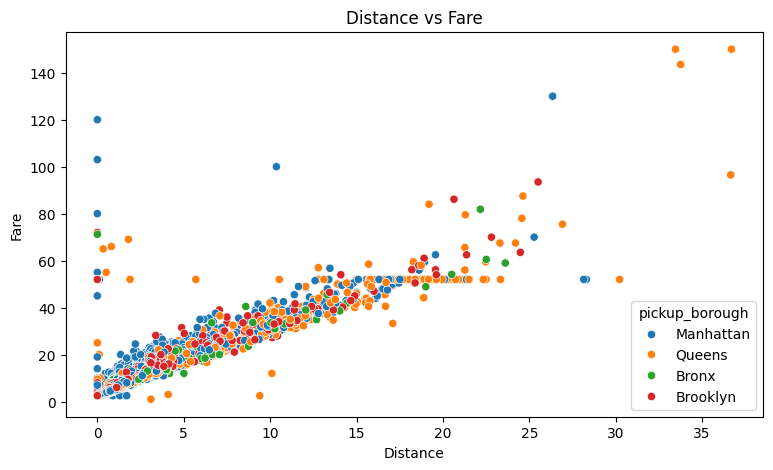

In [33]:
plt.figure(figsize=(9,5))
sns.scatterplot(x='distance',y='fare',data=df,hue='pickup_borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.title('Distance vs Fare')
plt.show()

x='distance' place trip distance on x axis

y='fare' places fare on y axis

hue=pickup borough uses different colors for different boroughs

HEAT MAP

Plot a heatmap to visualize the correlation between numerical variables sucha as distance,fare,tip,tolls and total . use a correlation matrix to show the relationship

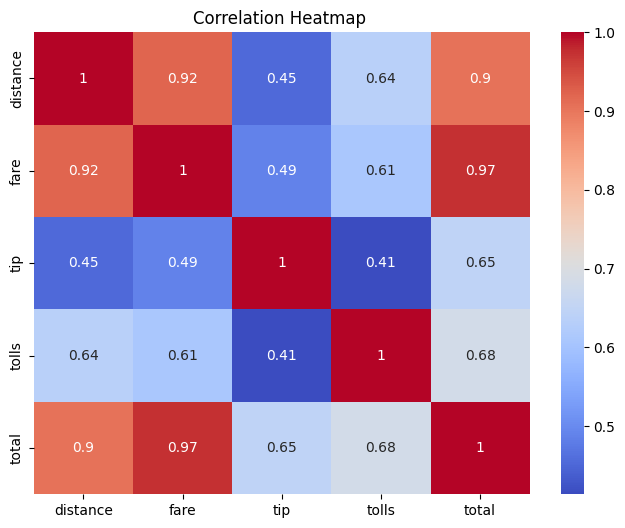

In [34]:
num_data=df[['distance','fare','tip','tolls','total']]
corr=num_data.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('Correlation Heatmap ')
plt.show()

num_data.corr() calculates the correlation between numerical variable

cmap=coolwarm set the clor scheme

PAIR PLOT

Create a pairplot to visualize the pairwise relationship between diatance, fare, tip and total color the data point according to the pickup zone method to compare how different zones affect the variables

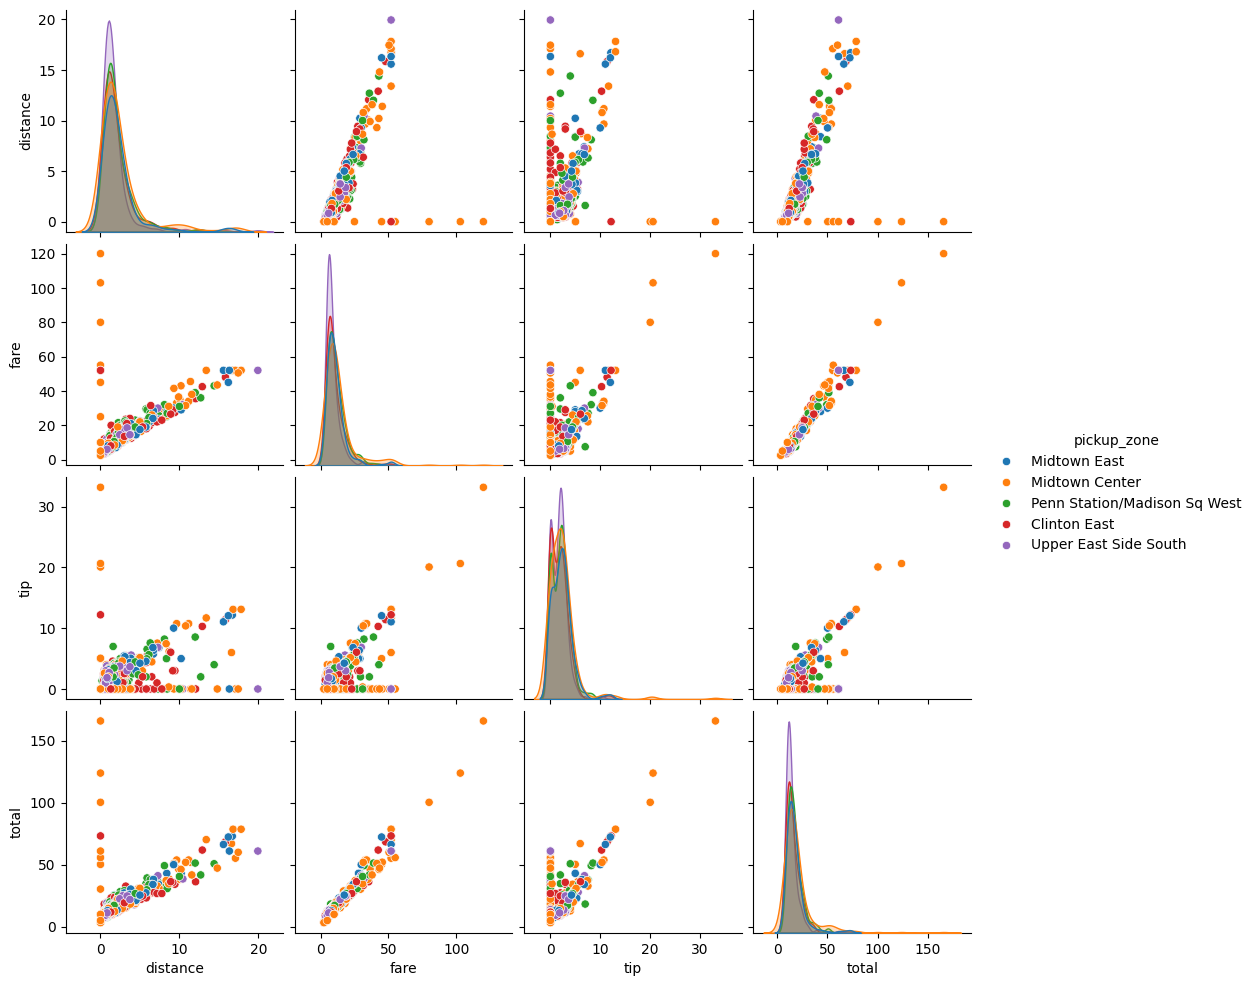

In [37]:
top_zones=df['pickup_zone'].value_counts().head(5).index
top_df=df[df['pickup_zone'].isin(top_zones)]
sns.pairplot(top_df,vars=['distance','fare','tip','total'],hue='pickup_zone')
plt.show()

value_counts.head(5) finds the five most frequent pickup zones

isin(topzones) select rows belonging to those zones

vars specify the numerical variables to compare

hue=pickup zone assigms color according to pickup zone

VIOLIN PLOT

Plot a violin plot to show the distribution of fare for each payment method.use the payment method as the categorical axis and fare as the numerical axis to visualize its distribution

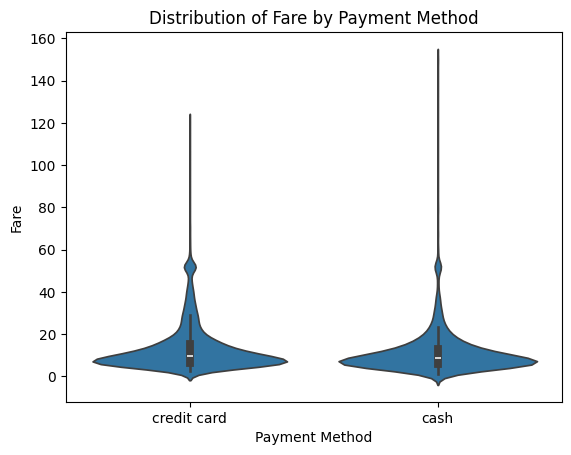

In [38]:
sns.violinplot(x='payment',y='fare',data=df)
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.title('Distribution of Fare by Payment Method')
plt.show()

x=payment display payment methods on x axis

y=fare display fare on y axis

sns.violinplot() shows the distribution and density of fares for each payment method